# Chapter 4: IO expiration parity — replication diagnostic

Textbook intrinsic-value curves are compared with option settlement, not trade execution or a strategy. Entry is the option settlement 20 observed trading days before expiry. The underlying at expiry is the matching IF future settlement. No fees or margin. The parity and realized points need not coincide.

In [1]:
%matplotlib inline
import json
import os
from datetime import date, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joseph_pilot.manifest import Manifest
from joseph_pilot.revision import load_revision, resolve_expiry, third_friday
from joseph_pilot.runtime import bootstrap

base = Path("notebooks/book-examples/natenberg-option-volatility-and-pricing/chapter-04-expiration-pnl")
manifest = Manifest.model_validate_json(Path(os.environ.get("PILOT_MANIFEST_PATH", base / "parity-io-2024-2025.manifest.json")).read_text())
assert manifest.experiment_id == "replication_diagnostic"
print("Data flow — economic conventions")
display(pd.DataFrame(list(manifest.economic_conventions.items()), columns=["convention", "value"]))
print("Verified revision pins")
display(pd.DataFrame([dict(capability=name, **pin.model_dump(mode="json")) for name, pin in manifest.inputs.items()]))
settings, _, _ = bootstrap()
assert settings.revision_root is not None
folders = {"option_contracts": "option_contracts", "option_bars": "option_bars", "index_bars": "index_bars-20231101", "futures_bars": "futures_bars"}
data = {}
for name, folder in folders.items():
    revision = load_revision(name, settings=settings.model_copy(update={"revision_root": settings.revision_root / folder}))
    assert revision.pin == manifest.inputs[name].model_copy(update={"calendar_unverified": None}), name
    data[name] = revision.rows
    print(f"{name}: verified {len(revision.rows)} rows")


Data flow — economic conventions


,convention,value
0,costs,no fees or margin
1,entry,settle twenty trading days before expiry
2,expiry,expiry-day option settle
3,underlying,matching IF futures settle on expiry day


Verified revision pins


,capability,revision_id,window,calendar_unverified,content_digest
0,futures_bars,futures_bars@lake:10816467902c4f1b90de130681f0...,2023-11-01..2026-11-26,None,bb2bab2072ab0093261db0889bbccdaa711128e9d103d7...
1,index_bars,index_bars@lake:f8ee741273f245019b12fb65783b01cd,2023-11-01..2026-11-26,None,759e389d0b7b050c3b283b14b2a6fd7af0d908f6c46b51...
2,option_bars,option_bars@lake:dd97f8582206451f831c53f4cc6afce2,2023-11-01..2026-11-26,"{'start': '2023-11-01', 'end': '2023-11-25'}",6be92b070ec3ebb2ae1e73963977b306526b559a2ff37e...
3,option_contracts,option_contracts@lake:7b6cf46c1f784f159e452edc...,NaN,None,290c616df591eca9f8965ba740a317ea942ba63a8c09c1...


option_contracts: verified 7000 rows


option_bars: verified 538864 rows
index_bars: verified 5816 rows
futures_bars: verified 20860 rows


In [2]:
contracts, bars, index, futures = (data[x] for x in ("option_contracts", "option_bars", "index_bars", "futures_bars"))
trading_days = sorted(set(index.loc[index.symbol == "000300.SH", "trade_date"]))
assert trading_days
calendar = {}
day = min(trading_days)
while day <= max(trading_days):
    calendar[day] = day in set(trading_days)
    day += timedelta(days=1)
contracts = contracts[contracts.symbol.str.match(r"^IO(24|25)\d{2}[CP]")].copy()
months = sorted(set(contracts.expiry_month))
rows, dropped, samples = [], [], []
for month in months:
    code = f"{month.year % 100:02d}{month.month:02d}"
    chain = contracts[contracts.expiry_month == month]
    obars = bars[bars.symbol.isin(chain.symbol)]
    future = futures[futures.symbol == f"IF{code}.CFE"]
    raw_friday = third_friday(month.year, month.month)
    expiry = next((d for d in trading_days if d >= raw_friday), None)
    future_last = max(future.trade_date) if not future.empty else None
    if expiry is None:
        dropped.append(dict(month=str(month)[:7], symbol=None, derived=None, option_last=None, future_last=str(future_last), reason="calendar does not cover expiry"))
        continue
    valid_symbols = []
    for contract in chain.itertuples():
        contract_bars = obars[obars.symbol == contract.symbol]
        option_last = max(contract_bars.trade_date) if not contract_bars.empty else None
        try:
            if option_last is None:
                raise ValueError("missing option bars")
            resolved = resolve_expiry(None, month, option_last, trading_calendar=calendar)
            if pd.notna(contract.expiry_date) and contract.expiry_date != resolved:
                raise ValueError("contract expiry date mismatch")
            if future_last != resolved:
                raise ValueError("IF last bar date mismatch")
        except ValueError as exc:
            dropped.append(dict(month=str(month)[:7], symbol=contract.symbol, derived=str(expiry), option_last=str(option_last) if option_last else None, future_last=str(future_last) if future_last else None, reason=str(exc)))
            continue
        valid_symbols.append(contract.symbol)
    chain = chain[chain.symbol.isin(valid_symbols)].copy()
    option_last = expiry
    if chain.empty:
        continue
    prior = [d for d in trading_days if d < expiry]
    if len(prior) < 20:
        dropped.append(dict(month=str(month)[:7], derived=str(expiry), option_last=str(option_last), future_last=str(future_last), reason="insufficient trading days"))
        continue
    entry = prior[-20]
    frow = future[future.trade_date == expiry]
    if len(frow) != 1 or pd.isna(frow.iloc[0].settle):
        dropped.append(dict(month=str(month)[:7], derived=str(expiry), option_last=str(option_last), future_last=str(future_last), reason="missing IF expiry settlement"))
        continue
    st = float(frow.iloc[0].settle)
    eligible = obars[obars.trade_date.isin([entry, expiry]) & obars.settle.notna()]
    complete = set(eligible.loc[eligible.trade_date == entry, "symbol"]) & set(eligible.loc[eligible.trade_date == expiry, "symbol"])
    chain = chain[chain.symbol.isin(complete)].copy()
    pairs = chain.groupby("strike").filter(lambda g: set(g.option_type.str.upper()) >= {"C", "P"})
    if pairs.empty:
        dropped.append(dict(month=str(month)[:7], derived=str(expiry), option_last=str(option_last), future_last=str(future_last), reason="no call/put pair with entry and expiry settlements"))
        continue
    strike = min(set(pairs.strike), key=lambda k: (abs(k-st), k))
    pair = pairs[pairs.strike == strike].sort_values("symbol")
    # Six evenly spread months per year, with all valid months as fallback.
    samples.append((month, expiry, entry, st, pair, eligible))
selected = []
for year in (2024, 2025):
    candidates = [v for v in samples if v[0].year == year]
    for target in (1, 3, 5, 7, 9, 11):
        if not candidates:
            break
        chosen = min(candidates, key=lambda v: (abs(v[0].month-target), v[0].month))
        selected.append(chosen)
        if chosen[0].month != target:
            print(f"Replacement for {year}-{target:02d}: {chosen[0].year}-{chosen[0].month:02d}")
        candidates.remove(chosen)
for pin in manifest.inputs.values():
    if pin.calendar_unverified is not None:
        assert all(sample[1] > pin.calendar_unverified.end for sample in selected), "selected expiry is in unverified calendar prefix"
for month, expiry, entry, st, pair, eligible in sorted(selected):
    for kind, name in (("C", "call"), ("P", "put")):
        contract = pair[pair.option_type.str.upper() == kind].iloc[0]
        values = eligible[eligible.symbol == contract.symbol].set_index("trade_date")
        premium, settlement = float(values.loc[entry, "settle"]), float(values.loc[expiry, "settle"])
        intrinsic = max(st-float(contract.strike), 0) if kind == "C" else max(float(contract.strike)-st, 0)
        for sign, direction in ((1, "Long"), (-1, "Short")):
            mult = float(contract.multiplier)
            rows.append(dict(third_friday=str(third_friday(month.year, month.month)), option_last=str(expiry), future_last=str(expiry), expiry=str(expiry), entry_date=str(entry), option_symbol=contract.symbol, future_symbol=f"IF{month.year % 100:02d}{month.month:02d}.CFE", position=f"{direction} {name}", entry_settle=premium, expiry_settle=settlement, if_settle=st, K=float(contract.strike), multiplier=mult, realized_pnl=sign*(settlement-premium)*mult, parity_pnl=sign*(intrinsic-premium)*mult, difference_points=sign*(settlement-intrinsic), curve_point=sign*(intrinsic-premium)*mult, tick_size=float(contract.tick_size)))
assert rows, "No valid expiries with complete data"
table = pd.DataFrame(rows)
print("Replication diagnostic — realized-vs-parity")
display(table.drop(columns=["curve_point", "tick_size"]))
print("Dropped expiries")
display(pd.DataFrame(dropped, columns=["month", "symbol", "derived", "option_last", "future_last", "reason"]))
print("Contracts with settlement/intrinsic difference greater than one tick")
display(table[(table.position.str.startswith("Long")) & (table.difference_points.abs() > table.tick_size)])


Replication diagnostic — realized-vs-parity


,third_friday,option_last,future_last,expiry,entry_date,option_symbol,future_symbol,position,entry_settle,expiry_settle,if_settle,K,multiplier,realized_pnl,parity_pnl,difference_points
0,2024-01-19,2024-01-19,2024-01-19,2024-01-19,2023-12-21,IO2401C3250.CFE,IF2401.CFE,Long call,123.0,16.82,3266.82,3250.0,100.0,-10618.0,-10618.0,-1.634248e-13
1,2024-01-19,2024-01-19,2024-01-19,2024-01-19,2023-12-21,IO2401C3250.CFE,IF2401.CFE,Short call,123.0,16.82,3266.82,3250.0,100.0,10618.0,10618.0,1.634248e-13
2,2024-01-19,2024-01-19,2024-01-19,2024-01-19,2023-12-21,IO2401P3250.CFE,IF2401.CFE,Long put,25.2,0.00,3266.82,3250.0,100.0,-2520.0,-2520.0,0.000000e+00
3,2024-01-19,2024-01-19,2024-01-19,2024-01-19,2023-12-21,IO2401P3250.CFE,IF2401.CFE,Short put,25.2,0.00,3266.82,3250.0,100.0,2520.0,2520.0,-0.000000e+00
4,2024-03-15,2024-03-15,2024-03-15,2024-03-15,2024-02-08,IO2403C3550.CFE,IF2403.CFE,Long call,25.8,4.21,3554.21,3550.0,100.0,-2159.0,-2159.0,-3.641532e-14
5,2024-03-15,2024-03-15,2024-03-15,2024-03-15,2024-02-08,IO2403C3550.CFE,IF2403.CFE,Short call,25.8,4.21,3554.21,3550.0,100.0,2159.0,2159.0,3.641532e-14
6,2024-03-15,2024-03-15,2024-03-15,2024-03-15,2024-02-08,IO2403P3550.CFE,IF2403.CFE,Long put,222.4,0.00,3554.21,3550.0,100.0,-22240.0,-22240.0,0.000000e+00
7,2024-03-15,2024-03-15,2024-03-15,2024-03-15,2024-02-08,IO2403P3550.CFE,IF2403.CFE,Short put,222.4,0.00,3554.21,3550.0,100.0,22240.0,22240.0,-0.000000e+00
8,2024-05-17,2024-05-17,2024-05-17,2024-05-17,2024-04-16,IO2405C3650.CFE,IF2405.CFE,Long call,18.8,0.00,3647.21,3650.0,100.0,-1880.0,-1880.0,0.000000e+00
9,2024-05-17,2024-05-17,2024-05-17,2024-05-17,2024-04-16,IO2405C3650.CFE,IF2405.CFE,Short call,18.8,0.00,3647.21,3650.0,100.0,1880.0,1880.0,-0.000000e+00


Dropped expiries


,month,symbol,derived,option_last,future_last,reason


Contracts with settlement/intrinsic difference greater than one tick


,third_friday,option_last,future_last,expiry,entry_date,option_symbol,future_symbol,position,entry_settle,expiry_settle,if_settle,K,multiplier,realized_pnl,parity_pnl,difference_points,curve_point,tick_size


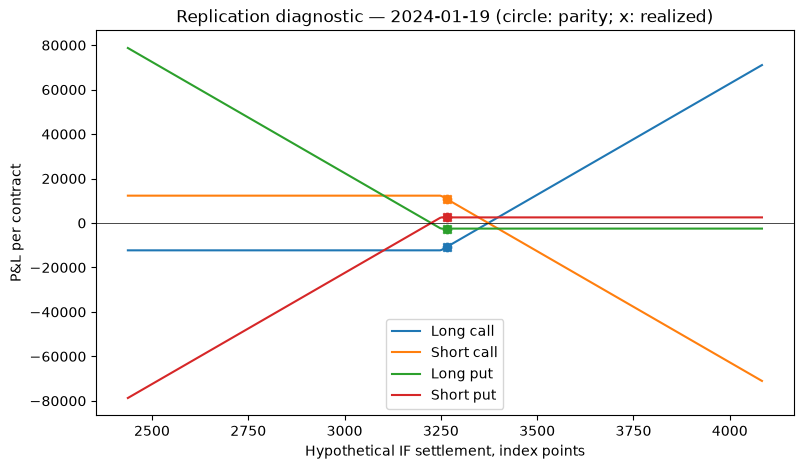

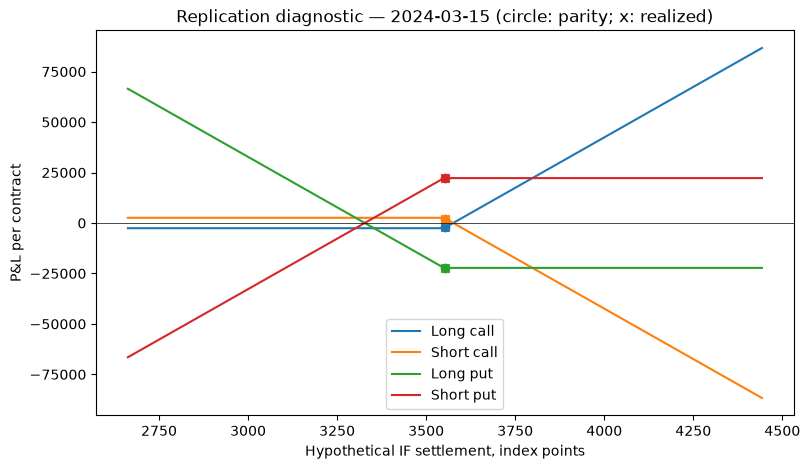

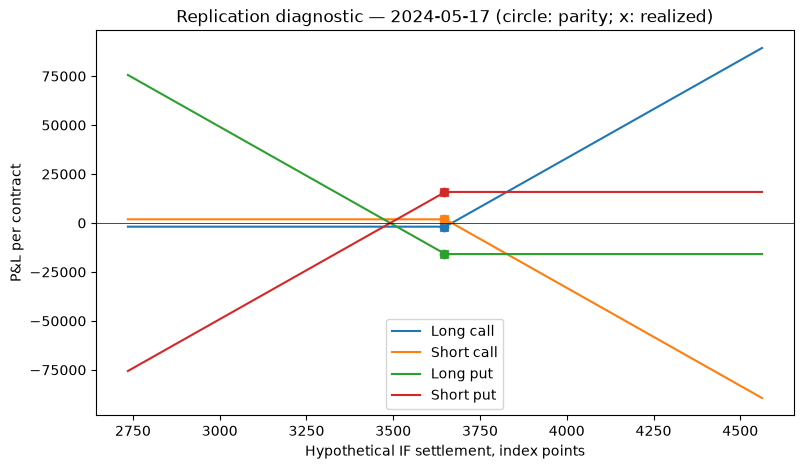

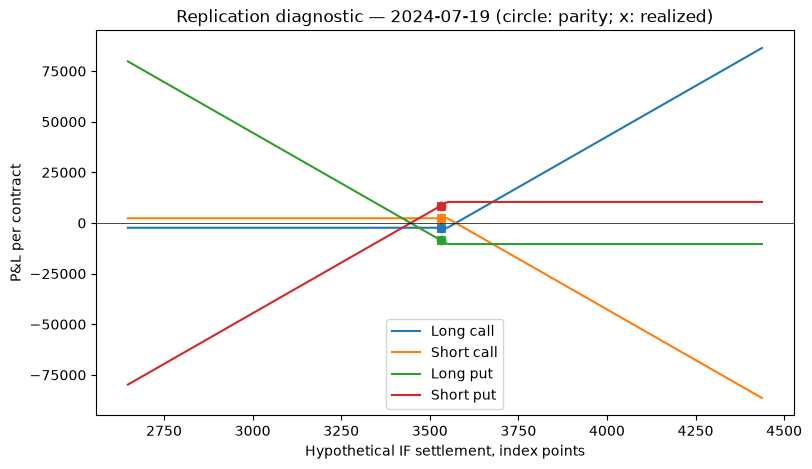

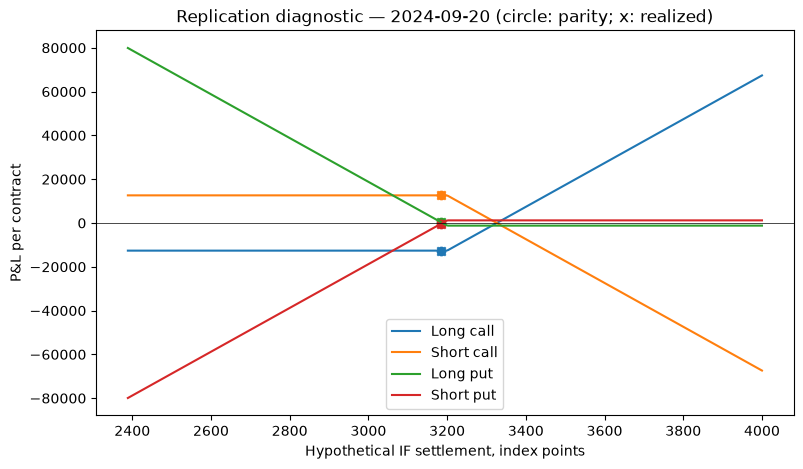

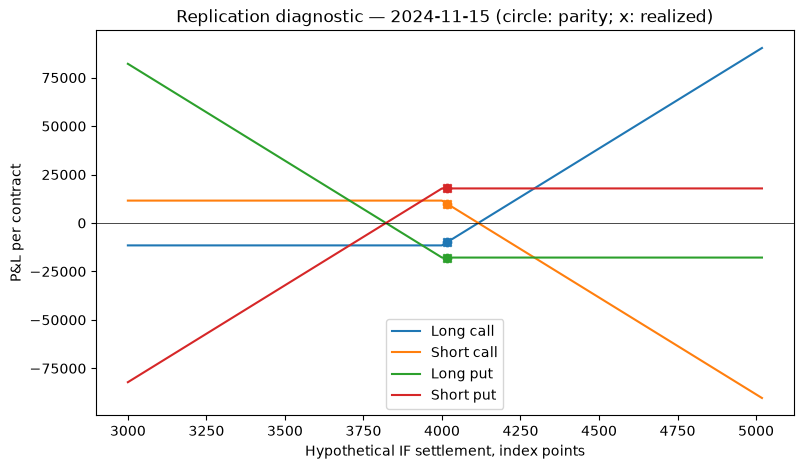

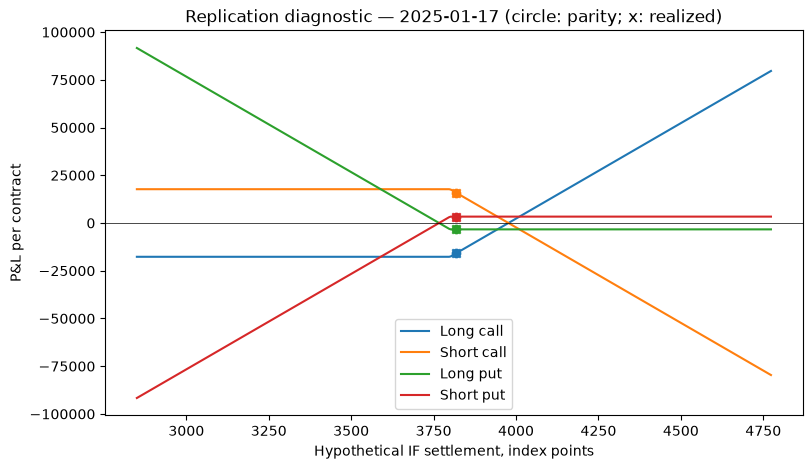

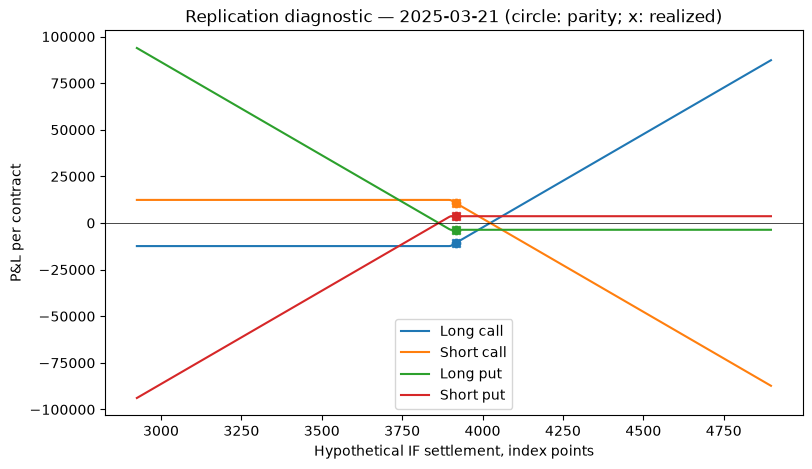

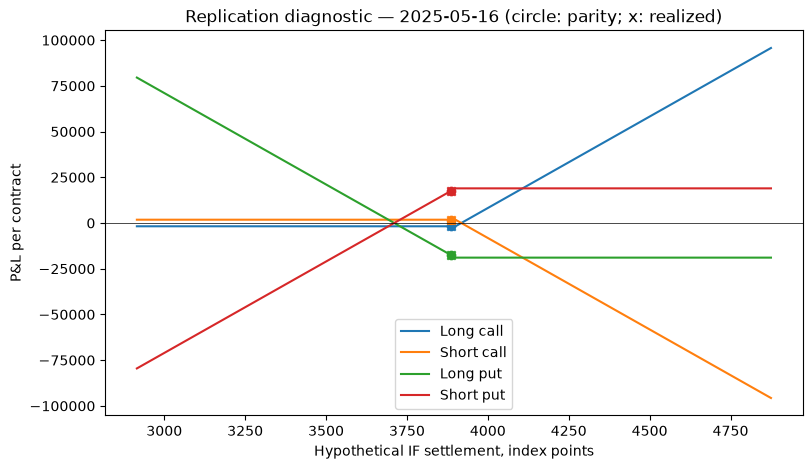

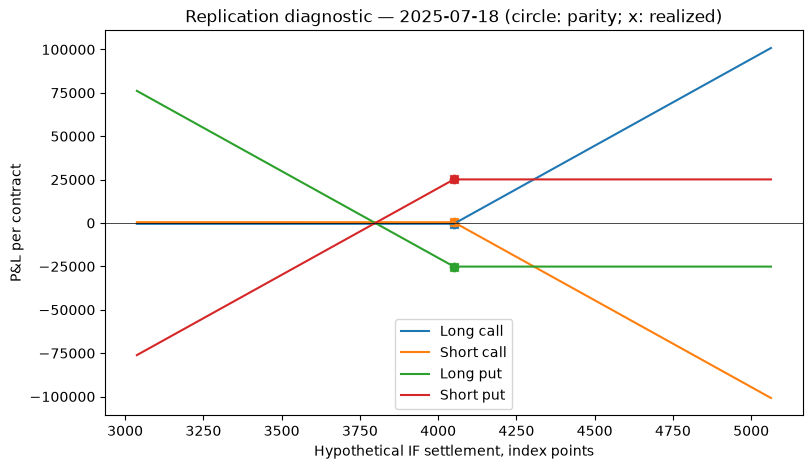

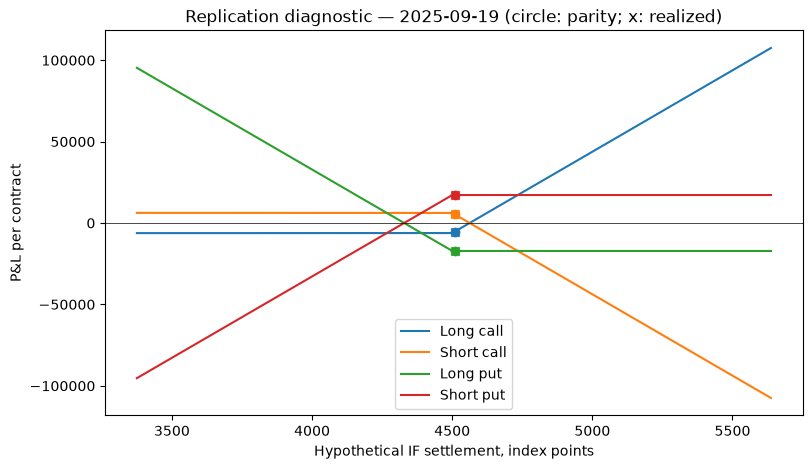

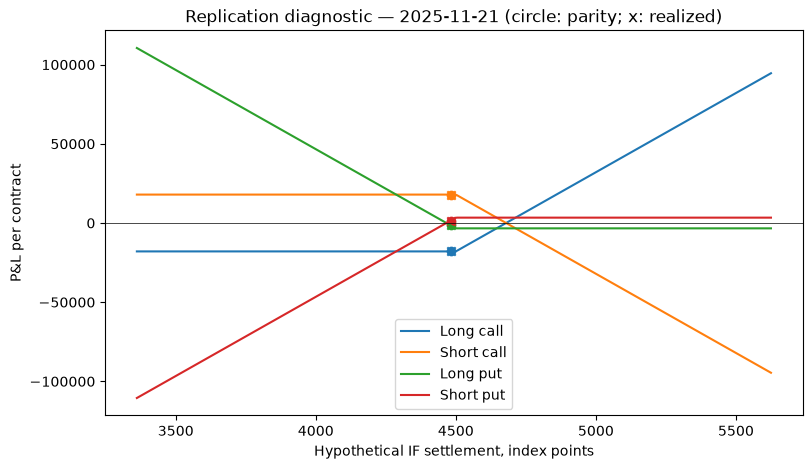

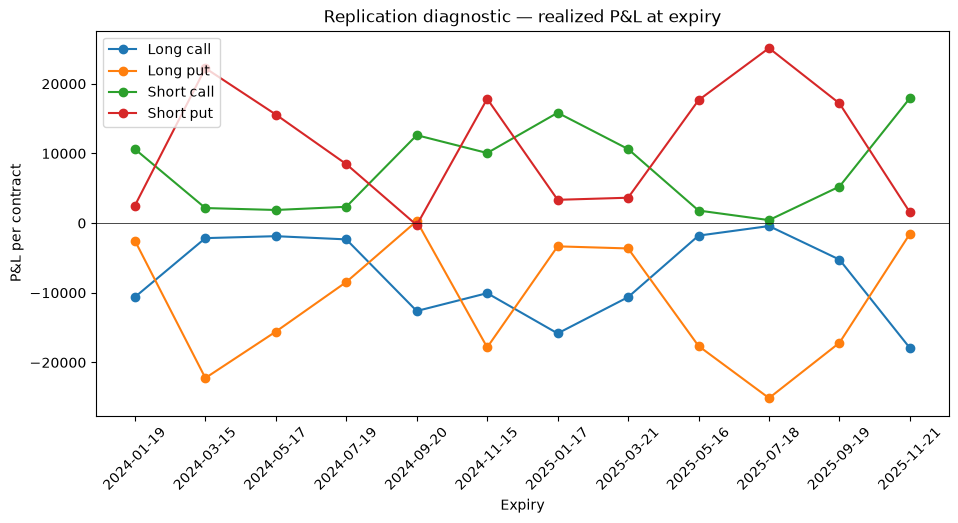

{"dropped": [], "rows": [{"K": 3250.0, "curve_point": -10617.999999999984, "difference_points": -1.6342482922482304e-13, "entry_date": "2023-12-21", "entry_settle": 123.0, "expiry": "2024-01-19", "expiry_settle": 16.82, "future_last": "2024-01-19", "future_symbol": "IF2401.CFE", "if_settle": 3266.82, "multiplier": 100.0, "option_last": "2024-01-19", "option_symbol": "IO2401C3250.CFE", "parity_pnl": -10617.999999999984, "position": "Long call", "realized_pnl": -10618.0, "third_friday": "2024-01-19", "tick_size": 0.2}, {"K": 3250.0, "curve_point": 10617.999999999984, "difference_points": 1.6342482922482304e-13, "entry_date": "2023-12-21", "entry_settle": 123.0, "expiry": "2024-01-19", "expiry_settle": 16.82, "future_last": "2024-01-19", "future_symbol": "IF2401.CFE", "if_settle": 3266.82, "multiplier": 100.0, "option_last": "2024-01-19", "option_symbol": "IO2401C3250.CFE", "parity_pnl": 10617.999999999984, "position": "Short call", "realized_pnl": 10618.0, "third_friday": "2024-01-19", "

In [3]:
for expiry, group in table.groupby("expiry", sort=True):
    fig, ax = plt.subplots(figsize=(9, 5))
    low = min(group.K.min(), group.if_settle.min()) * .75
    high = max(group.K.max(), group.if_settle.max()) * 1.25
    x = np.linspace(low, high, 401)
    for row in group.itertuples():
        intrinsic = np.maximum(x-row.K, 0) if "call" in row.position else np.maximum(row.K-x, 0)
        sign = 1 if row.position.startswith("Long") else -1
        line, = ax.plot(x, sign*(intrinsic-row.entry_settle)*row.multiplier, label=row.position)
        ax.scatter([row.if_settle], [row.parity_pnl], color=line.get_color(), marker="o")
        ax.scatter([row.if_settle], [row.realized_pnl], color=line.get_color(), marker="x")
    ax.axhline(0, color="black", linewidth=.5)
    ax.set(title=f"Replication diagnostic — {expiry} (circle: parity; x: realized)", xlabel="Hypothetical IF settlement, index points", ylabel="P&L per contract")
    ax.legend()
    plt.show()
fig, ax = plt.subplots(figsize=(11, 5))
for name, group in table.groupby("position"):
    ax.plot(group.expiry, group.realized_pnl, marker="o", label=name)
ax.axhline(0, color="black", linewidth=.5)
ax.set(title="Replication diagnostic — realized P&L at expiry", xlabel="Expiry", ylabel="P&L per contract")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.show()
print(json.dumps({"rows": rows, "dropped": dropped}, sort_keys=True))
